# **Assignment 07**

---

## **Import External Libraries**

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

from IPython.display import display, Math

from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService

---

## **1. Z-Gate**

In [2]:
# --- Problem 1: the Z-gate turns |-> into |+> ---
def latex_matrix(M):
    """LaTeX for a numeric array: rounded to 4 d.p., whole numbers shown as integers."""
    M = np.round(np.real_if_close(np.asarray(M, dtype=complex)), 4) + 0.0
    return sp.latex(sp.Matrix(M).applyfunc(lambda v: sp.Integer(int(v)) if float(v).is_integer() else v))


Z     = np.array([[1, 0], [0, -1]])
plus  = np.array([1,  1]) / np.sqrt(2)
minus = np.array([1, -1]) / np.sqrt(2)

display(Math(r"Z\ket{-} = " + latex_matrix(Z @ minus)))
print("Problem 1  --  Z|-> == |+> ?", np.allclose(Z @ minus, plus))
print("Problem 1  --  Z|+> == |-> ?", np.allclose(Z @ plus, minus))

<IPython.core.display.Math object>

Problem 1  --  Z|-> == |+> ? True
Problem 1  --  Z|+> == |-> ? True


---

## **2. Controlled-Z Gate**

In [3]:
# --- Problem 2: controlled-Z from the controlled phase shift, and CZ as a CNOT in the +/- basis ---
I2 = np.eye(2)
X  = np.array([[0, 1], [1, 0]])
H  = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
P0 = np.array([[1, 0], [0, 0]])   # |0><0|
P1 = np.array([[0, 0], [0, 1]])   # |1><1|


def CP(phi):
    """Controlled phase shift with the MSB as control: |0><0| (x) I + |1><1| (x) P(phi)."""
    return np.kron(P0, I2) + np.kron(P1, np.diag([1, np.exp(1j * phi)]))


CZ   = CP(np.pi)
CNOT = np.kron(P0, I2) + np.kron(P1, X)

display(Math(r"CP(\pi) = " + latex_matrix(CZ)))
print("Problem 2  --  CP(pi) == diag(1, 1, 1, -1) ?", np.allclose(CZ, np.diag([1, 1, 1, -1])))

print("---------------")

# target in the |+>/|-> basis: change basis with I (x) H  (H|0> = |+>, H|1> = |->)
CZ_pm = np.kron(I2, H) @ CZ @ np.kron(I2, H)
display(Math(r"(I \otimes H)\,CZ\,(I \otimes H) = " + latex_matrix(CZ_pm)))
print("Problem 2  --  equals CNOT ?", np.allclose(CZ_pm, CNOT))
print("Problem 2  --  CZ|1+> == |1-> ?", np.allclose(CZ @ np.kron([0, 1], plus), np.kron([0, 1], minus)))

<IPython.core.display.Math object>

Problem 2  --  CP(pi) == diag(1, 1, 1, -1) ? True
---------------


<IPython.core.display.Math object>

Problem 2  --  equals CNOT ? True
Problem 2  --  CZ|1+> == |1-> ? True


---

## **3. Implementation of a SWAP gate**

In [4]:
# --- Problem 3: SWAP from CNOT (MSB ctrl), CNOT (LSB ctrl), CNOT (MSB ctrl) ---
def basis(bits):
    """|b1 b0> as a length-4 vector, MSB first."""
    v = np.zeros(4)
    v[int(bits, 2)] = 1
    return v


def gate_from_map(f):
    """Matrix whose column |j> is f(|j>), i.e. built from the gate's truth table."""
    return np.column_stack([basis(f(format(j, "02b"))) for j in range(4)])


C_M  = gate_from_map(lambda ab: ab[0] + str(int(ab[0]) ^ int(ab[1])))   # |a b> -> |a, a xor b>
C_L  = gate_from_map(lambda ab: str(int(ab[0]) ^ int(ab[1])) + ab[1])   # |a b> -> |a xor b, b>
SWAP = gate_from_map(lambda ab: ab[::-1])                               # |a b> -> |b a>

display(Math(r"C_L = " + latex_matrix(C_L)))
display(Math(r"C_M\,C_L\,C_M = " + latex_matrix(C_M @ C_L @ C_M)))
print("Problem 3  --  C_M equals the CNOT of Problem 2 ?", np.allclose(C_M, CNOT))
print("Problem 3  --  C_M C_L C_M == SWAP ?", np.allclose(C_M @ C_L @ C_M, SWAP))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 3  --  C_M equals the CNOT of Problem 2 ? True
Problem 3  --  C_M C_L C_M == SWAP ? True


---

## **4. 1-qubit Hadamard Gate**

In [5]:
# --- Problem 4: H (alpha|0> + beta|1>) = alpha|+> + beta|-> ---
alpha, beta = sp.symbols("alpha beta")
H_sym     = sp.Matrix([[1, 1], [1, -1]]) / sp.sqrt(2)
plus_sym  = sp.Matrix([1,  1]) / sp.sqrt(2)
minus_sym = sp.Matrix([1, -1]) / sp.sqrt(2)

lhs = H_sym * sp.Matrix([alpha, beta])
rhs = alpha * plus_sym + beta * minus_sym

display(Math(r"H\ket{\psi} = " + sp.latex(lhs)))
display(Math(r"\alpha\ket{+} + \beta\ket{-} = " + sp.latex(sp.simplify(rhs))))
print("Problem 4  --  equal?", sp.simplify(lhs - rhs) == sp.zeros(2, 1))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 4  --  equal? True


---

## **5–7. n-qubit Hadamard Gate (Problems 5–7)**

In [6]:
# --- Problems 5-7: H^{(x)2}|2> three ways ---
n, y = 2, 2


def dot_mod2(x, y):
    """Bitwise inner product x . y taken mod 2."""
    return bin(x & y).count("1") % 2


# Problem 5: the sum formula  (1 / 2^{n/2}) sum_x (-1)^{x.y} |x>
formula = np.array([(-1) ** dot_mod2(x, y) for x in range(2 ** n)]) / 2 ** (n / 2)

# Problem 6: the expansion  (H|y1>) (x) (H|y0>)
ket = [np.array([1, 0]), np.array([0, 1])]
y1, y0 = divmod(y, 2)
expansion = np.kron(H @ ket[y1], H @ ket[y0])

# Problem 7: matrix multiplication  (H (x) H)|2>
display(Math(r"H \otimes H = " + latex_matrix(np.kron(H, H))))
matrix = np.kron(H, H) @ basis(format(y, "02b"))

print("n =", n)
for name, vec in [("Problem 5 (formula)", formula),
                  ("Problem 6 (expansion)", expansion),
                  ("Problem 7 (matrix)", matrix)]:
    display(Math(r"\text{" + name + r"}: \; H^{\otimes 2}\ket{2} = " + latex_matrix(vec.reshape(1, -1))))
print("Problems 5-7  --  all equal?", np.allclose(formula, expansion) and np.allclose(expansion, matrix))

<IPython.core.display.Math object>

n = 2


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problems 5-7  --  all equal? True


---

## **8. SWAP Gate Implementation**

In [7]:
# --- Problem 8: SWAP from CNOT (LSB ctrl), CNOT (MSB ctrl), CNOT (LSB ctrl) ---
display(Math(r"C_M\,C_L = " + latex_matrix(C_M @ C_L)))
display(Math(r"C_L\,C_M\,C_L = " + latex_matrix(C_L @ C_M @ C_L)))
print("Problem 8  --  C_L C_M C_L == SWAP ?", np.allclose(C_L @ C_M @ C_L, SWAP))

print("---------------")

# intuition method: follow every basis state through the three gates
for j in range(4):
    v = basis(format(j, "02b"))
    path = [v, C_L @ v, C_M @ C_L @ v, C_L @ C_M @ C_L @ v]
    print("  ->  ".join(f"|{format(int(np.argmax(s)), '02b')}>" for s in path))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 8  --  C_L C_M C_L == SWAP ? True
---------------
|00>  ->  |00>  ->  |00>  ->  |00>
|01>  ->  |11>  ->  |10>  ->  |10>
|10>  ->  |10>  ->  |11>  ->  |01>
|11>  ->  |01>  ->  |01>  ->  |11>


---

## **9. LSB-controlling CNOT Gate**

In [8]:
# --- Problem 9: derive the LSB-controlling CNOT from its definition ---
# U = sum_{a,b} |a xor b, b><a b|   (one outer product |output><input| per truth-table row)
U_center = sum(np.outer(basis(f"{a ^ b}{b}"), basis(f"{a}{b}")) for a in (0, 1) for b in (0, 1))
display(Math(r"U_{\text{XOR},\text{center}} = " + latex_matrix(U_center)))
print("Problem 9  --  equals C_L ?", np.allclose(U_center, C_L))
print("Problem 9  --  equals I (x) |0><0| + X (x) |1><1| ?", np.allclose(U_center, np.kron(I2, P0) + np.kron(X, P1)))
print("Problem 9  --  equals SWAP C_M SWAP ?", np.allclose(U_center, SWAP @ C_M @ SWAP))

print("---------------")

U_left = U_right = C_M
display(Math(r"U_{\text{XOR},\text{right}}\,U_{\text{XOR},\text{center}} = " + latex_matrix(U_right @ U_center)))
print("Problem 9  --  U_right U_center U_left == SWAP ?", np.allclose(U_right @ U_center @ U_left, SWAP))

<IPython.core.display.Math object>

Problem 9  --  equals C_L ? True
Problem 9  --  equals I (x) |0><0| + X (x) |1><1| ? True
Problem 9  --  equals SWAP C_M SWAP ? True
---------------


<IPython.core.display.Math object>

Problem 9  --  U_right U_center U_left == SWAP ? True


---

## **10. Quantum Computing Exercise 1**

In [9]:
# --- Problem 10: the basis-transformation circuit of Figure 1, then with input |11> ---
SHOTS = 1024
rng = np.random.default_rng(2110515)


def run(gates, label, shots=SHOTS):
    """Apply the gates (in time order) to |00>; print exact probabilities and sampled counts."""
    state = basis("00")
    for g in gates:
        state = g @ state
    probs = np.abs(state) ** 2
    counts = rng.multinomial(shots, probs / probs.sum())
    display(Math(label + " = " + latex_matrix(state.reshape(1, -1))))
    for k in range(4):
        print(f"  {format(k, '02b')}:  P = {probs[k]:7.2%}   simulated counts = {counts[k]:4d} / {shots}")
    return state


X_M, X_L, H_M = np.kron(X, I2), np.kron(I2, X), np.kron(H, I2)   # MSB is the first tensor factor

print("Figure 1 as given (input |00>; the I gate on q0 does nothing):")
run([H_M, C_M], r"(\text{CNOT})(H \otimes I)\ket{00}")

print("---------------")

print("Modified: X on both qubits first (input |11>):")
out = run([X_M, X_L, H_M, C_M], r"(\text{CNOT})(H \otimes I)\ket{11}")
psi_minus = (basis("01") - basis("10")) / np.sqrt(2)
print("Problem 10  --  output == |psi^-> ?", np.allclose(out, psi_minus))

Figure 1 as given (input |00>; the I gate on q0 does nothing):


<IPython.core.display.Math object>

  00:  P =  50.00%   simulated counts =  536 / 1024
  01:  P =   0.00%   simulated counts =    0 / 1024
  10:  P =   0.00%   simulated counts =    0 / 1024
  11:  P =  50.00%   simulated counts =  488 / 1024
---------------
Modified: X on both qubits first (input |11>):


<IPython.core.display.Math object>

  00:  P =   0.00%   simulated counts =    0 / 1024
  01:  P =  50.00%   simulated counts =  507 / 1024
  10:  P =  50.00%   simulated counts =  517 / 1024
  11:  P =   0.00%   simulated counts =    0 / 1024
Problem 10  --  output == |psi^-> ? True


---

## **11. Quantum Computing Exercise 2**

In [10]:
# --- Problem 11: the SWAP circuit of Figure 2 with input |10> (X on the MSB) ---
out = run([X_M, C_M, C_L, C_M], r"C_M\,C_L\,C_M\ket{10}")
print("Problem 11  --  output == |01> ?", np.allclose(out, basis("01")))

<IPython.core.display.Math object>

  00:  P =   0.00%   simulated counts =    0 / 1024
  01:  P = 100.00%   simulated counts = 1024 / 1024
  10:  P =   0.00%   simulated counts =    0 / 1024
  11:  P =   0.00%   simulated counts =    0 / 1024
Problem 11  --  output == |01> ? True


---

## **12. Quantum Computing Exercise 3**

In [11]:
# --- Problem 12: input |01> as in Figure 3 -- three CNOTs vs. the SWAP gate directly ---
print("Three CNOTs (Figure 3):")
out_cnot = run([X_L, C_M, C_L, C_M], r"C_M\,C_L\,C_M\ket{01}")

print("---------------")

print("SWAP gate directly:")
out_swap = run([X_L, SWAP], r"U_{\text{SWAP}}\ket{01}")
print("Problem 12  --  identical outputs?", np.allclose(out_cnot, out_swap))

Three CNOTs (Figure 3):


<IPython.core.display.Math object>

  00:  P =   0.00%   simulated counts =    0 / 1024
  01:  P =   0.00%   simulated counts =    0 / 1024
  10:  P = 100.00%   simulated counts = 1024 / 1024
  11:  P =   0.00%   simulated counts =    0 / 1024
---------------
SWAP gate directly:


<IPython.core.display.Math object>

  00:  P =   0.00%   simulated counts =    0 / 1024
  01:  P =   0.00%   simulated counts =    0 / 1024
  10:  P = 100.00%   simulated counts = 1024 / 1024
  11:  P =   0.00%   simulated counts =    0 / 1024
Problem 12  --  identical outputs? True


---

## **10–12. Running on IBM Quantum (Problems 10–12)**

In [12]:
# --- Problems 10-12 on IBM Quantum: AerSimulator vs. real hardware ---
# Each hardware job was submitted once (one Sampler job holding all five circuits, 1024 shots each).
# Re-running this notebook only *fetches* the results, so no further QPU time is spent.
HW_JOB_ID    = "dar2ndrt55cs738sgol0"   # ibm_marrakesh, pinned to the best-calibrated pair (153, 154)
FIRST_JOB_ID = "dar2lobt55cs738sgmo0"   # first attempt: ibm_kingston, default layout (0, 1) -- see the last cell
SHOTS = 1024


def figure1(prepare_11):
    """Figure 1: H on the MSB (q1), then CNOT q1 -> q0. prepare_11 turns the I on q0 into X and adds X on q1."""
    qc = QuantumCircuit(2, 2)
    if prepare_11:
        qc.x([0, 1])
    else:
        qc.id(0)
    qc.h(1)
    qc.cx(1, 0)
    qc.measure([0, 1], [0, 1])
    return qc


def swap_circuit(input_q1q0, direct):
    """Figures 2/3: prepare |q1 q0>, then SWAP as three CNOTs (C_M, C_L, C_M) or as one SWAP gate."""
    qc = QuantumCircuit(2, 2)
    if input_q1q0[0] == "1":
        qc.x(1)
    if input_q1q0[1] == "1":
        qc.x(0)
    if direct:
        qc.swap(0, 1)
    else:
        qc.cx(1, 0)
        qc.cx(0, 1)
        qc.cx(1, 0)
    qc.measure([0, 1], [0, 1])
    return qc


# same order as the PUBs of the submitted job
CIRCUITS = {
    "p10_input00": figure1(prepare_11=False),
    "p10_input11": figure1(prepare_11=True),
    "p11_cnot_input10": swap_circuit("10", direct=False),
    "p12_cnot_input01": swap_circuit("01", direct=False),
    "p12_swap_input01": swap_circuit("01", direct=True),
}

sim = AerSimulator(seed_simulator=2110515)
sim_counts = {name: sim.run(qc, shots=SHOTS).result().get_counts() for name, qc in CIRCUITS.items()}

service = QiskitRuntimeService()   # saved default account (set up in Lab 00)
hw_job = service.job(HW_JOB_ID)
hw_result = hw_job.result()
hw_counts = {name: hw_result[i].data.c.get_counts() for i, name in enumerate(CIRCUITS)}
backend_name = hw_job.backend().name
print(f"Hardware job {HW_JOB_ID} on {backend_name}: {hw_job.status()}")


def draw(name):
    fig = CIRCUITS[name].draw("mpl")
    display(fig)
    plt.close(fig)


def report(name, label):
    """Counts per bit string c1c0 (the composer's order): simulator vs. hardware."""
    print(label)
    for k in ("00", "01", "10", "11"):
        s, h = sim_counts[name].get(k, 0), hw_counts[name].get(k, 0)
        print(f"  {k}:  simulator {s:4d}   {backend_name} {h:4d}  ({h / SHOTS:6.2%})")


def histogram(names, labels, title, filename):
    """Grouped simulator/hardware histogram, also saved to ../images for the report."""
    data = [counts[n] for n in names for counts in (sim_counts, hw_counts)]
    legend = [f"{lbl}: {src}" for lbl in labels for src in ("simulator", backend_name)]
    fig = plot_histogram(data, legend=legend, title=title, figsize=(9, 4), bar_labels=False)
    fig.savefig(f"../images/{filename}", dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)

Hardware job dar2ndrt55cs738sgol0 on ibm_marrakesh: DONE


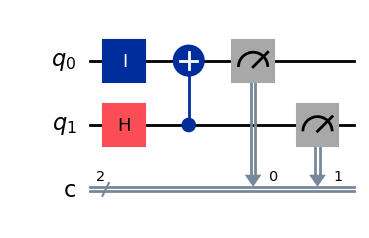

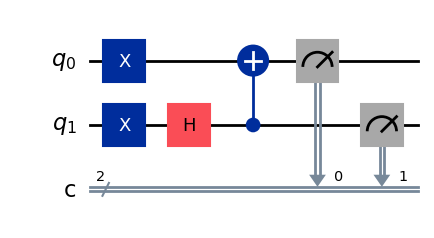

Figure 1, input |00>  (expected |phi+>: 00 / 11)
  00:  simulator  521   ibm_marrakesh  519  (50.68%)
  01:  simulator    0   ibm_marrakesh    5  ( 0.49%)
  10:  simulator    0   ibm_marrakesh   10  ( 0.98%)
  11:  simulator  503   ibm_marrakesh  490  (47.85%)
Figure 1, input |11>  (expected |psi->: 01 / 10)
  00:  simulator    0   ibm_marrakesh   15  ( 1.46%)
  01:  simulator  503   ibm_marrakesh  498  (48.63%)
  10:  simulator  521   ibm_marrakesh  506  (49.41%)
  11:  simulator    0   ibm_marrakesh    5  ( 0.49%)


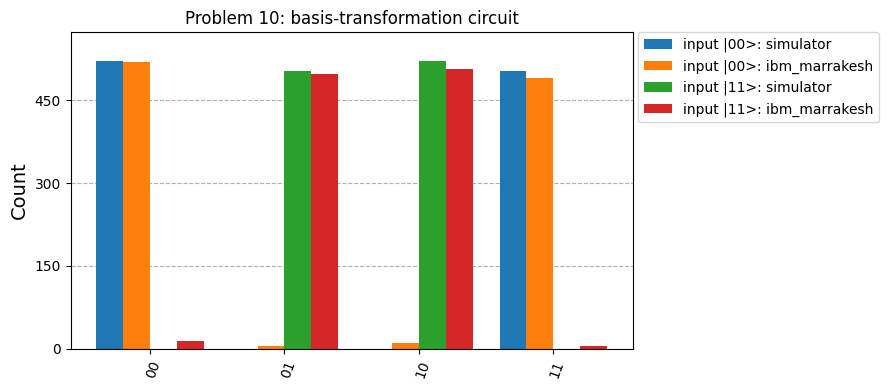

In [13]:
# --- Problem 10: Figure 1 as given (input |00>) and with input |11> ---
draw("p10_input00")
draw("p10_input11")
report("p10_input00", "Figure 1, input |00>  (expected |phi+>: 00 / 11)")
report("p10_input11", "Figure 1, input |11>  (expected |psi->: 01 / 10)")
histogram(["p10_input00", "p10_input11"], ["input |00>", "input |11>"],
          "Problem 10: basis-transformation circuit", "problem-10-answer.png")

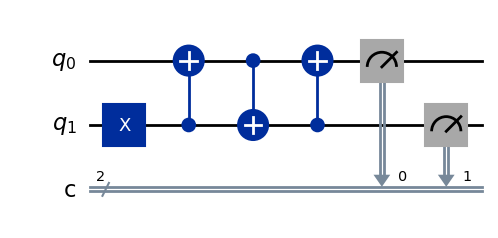

SWAP (3 CNOTs), input |10>  (expected 01)
  00:  simulator    0   ibm_marrakesh   19  ( 1.86%)
  01:  simulator 1024   ibm_marrakesh  989  (96.58%)
  10:  simulator    0   ibm_marrakesh    9  ( 0.88%)
  11:  simulator    0   ibm_marrakesh    7  ( 0.68%)


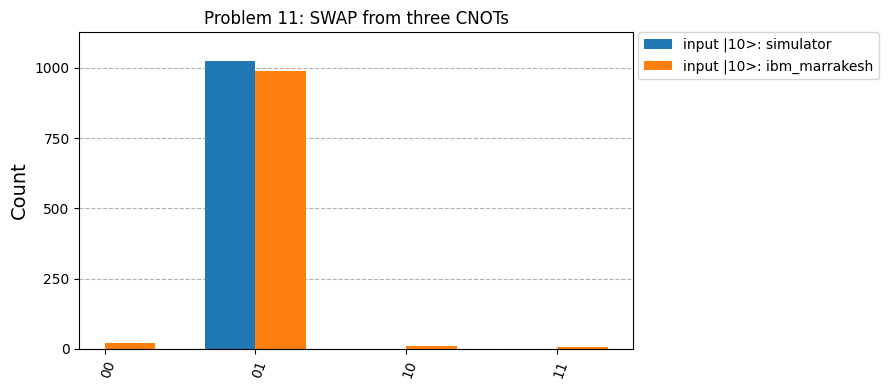

In [14]:
# --- Problem 11: SWAP circuit (three CNOTs) with input |10> ---
draw("p11_cnot_input10")
report("p11_cnot_input10", "SWAP (3 CNOTs), input |10>  (expected 01)")
histogram(["p11_cnot_input10"], ["input |10>"],
          "Problem 11: SWAP from three CNOTs", "problem-11-answer.png")

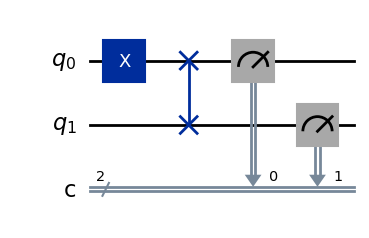

Three CNOTs, input |01>  (expected 10)
  00:  simulator    0   ibm_marrakesh   16  ( 1.56%)
  01:  simulator    0   ibm_marrakesh    8  ( 0.78%)
  10:  simulator 1024   ibm_marrakesh  993  (96.97%)
  11:  simulator    0   ibm_marrakesh    7  ( 0.68%)
SWAP gate,   input |01>  (expected 10)
  00:  simulator    0   ibm_marrakesh   18  ( 1.76%)
  01:  simulator    0   ibm_marrakesh   10  ( 0.98%)
  10:  simulator 1024   ibm_marrakesh  986  (96.29%)
  11:  simulator    0   ibm_marrakesh   10  ( 0.98%)


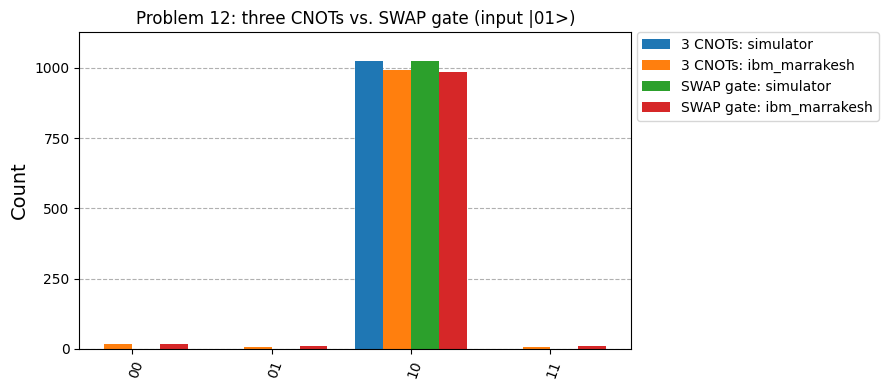

---------------


  optimization level 1, p12_cnot_input01: 3 CZ gate(s)
  optimization level 1, p12_swap_input01: 3 CZ gate(s)
  optimization level 3, p12_cnot_input01: 3 CZ gate(s)
  optimization level 3, p12_swap_input01: 0 CZ gate(s)


In [15]:
# --- Problem 12: input |01> -- three CNOTs (Figure 3) vs. the SWAP gate directly ---
draw("p12_swap_input01")
report("p12_cnot_input01", "Three CNOTs, input |01>  (expected 10)")
report("p12_swap_input01", "SWAP gate,   input |01>  (expected 10)")
histogram(["p12_cnot_input01", "p12_swap_input01"], ["3 CNOTs", "SWAP gate"],
          "Problem 12: three CNOTs vs. SWAP gate (input |01>)", "problem-12-answer.png")

print("---------------")

# what the transpiler actually runs on the device (native two-qubit gate: CZ)
backend = service.backend(backend_name)
for level in (1, 3):
    pm = generate_preset_pass_manager(optimization_level=level, backend=backend, seed_transpiler=7)
    for name in ("p12_cnot_input01", "p12_swap_input01"):
        print(f"  optimization level {level}, {name}: {pm.run(CIRCUITS[name]).count_ops().get('cz', 0)} CZ gate(s)")

In [16]:
# --- The first hardware attempt (ibm_kingston, physical qubits 0 and 1) ---
# Same five circuits, default layout. The circuits it ran simulate perfectly, yet the device returned
# far noisier counts than its calibration data predicts, so the job was re-run on the best-calibrated
# qubit pair (the results used above). Both runs are kept for comparison.
EXPECTED = {
    "p10_input00": ("00", "11"),
    "p10_input11": ("01", "10"),
    "p11_cnot_input10": ("01",),
    "p12_cnot_input01": ("10",),
    "p12_swap_input01": ("10",),
}
first_job = service.job(FIRST_JOB_ID)
first_result = first_job.result()
print(f"share of shots on the expected outcome(s):   {first_job.backend().name} (0, 1)   vs.   {backend_name}")
for i, name in enumerate(CIRCUITS):
    first = first_result[i].data.c.get_counts()
    ok_first = sum(first.get(k, 0) for k in EXPECTED[name]) / SHOTS
    ok_best = sum(hw_counts[name].get(k, 0) for k in EXPECTED[name]) / SHOTS
    print(f"  {name:18s}  {ok_first:7.1%}   vs.   {ok_best:6.1%}")

share of shots on the expected outcome(s):   ibm_kingston (0, 1)   vs.   ibm_marrakesh
  p10_input00           66.6%   vs.    98.5%
  p10_input11           56.9%   vs.    98.0%
  p11_cnot_input10      50.0%   vs.    96.6%
  p12_cnot_input01      37.8%   vs.    97.0%
  p12_swap_input01      39.8%   vs.    96.3%


---